In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd

# Importación desde el paquete modular refactorizado
from datascience_toolkit import (
    EDAQuick,
    EDAAdvanced,
    SupervisedClassification,   # Alias de ClassificationTournament
    DFPreprocess,
)

In [2]:
df = pd.read_csv("../data/hotel_bookings_v1.csv")

In [3]:
df.head(6)

,hotel,is_canceled,lead_time,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,previous_cancellations,previous_bookings_not_canceled,assigned_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,Resort Hotel,Yes,74,January,1,0,2,0,0,0,0,A,0,No Deposit,0,Transient,57.60,0,0
1,Resort Hotel,Yes,62,January,2,2,2,0,0,0,0,A,0,No Deposit,0,Transient,51.50,0,1
2,Resort Hotel,Yes,62,January,2,2,2,0,0,0,0,A,0,No Deposit,0,Transient,51.50,0,1
3,Resort Hotel,Yes,62,January,2,2,2,0,0,0,0,A,0,No Deposit,0,Transient,51.50,0,1
4,Resort Hotel,Yes,71,January,2,2,1,0,0,0,0,A,0,No Deposit,0,Transient,32.22,0,1
5,Resort Hotel,Yes,88,January,2,3,2,0,0,0,0,A,0,No Deposit,0,Transient,44.64,0,1


In [4]:
df["is_canceled"].value_counts()

is_canceled
Yes    10978
No      9401
Name: count, dtype: int64

In [5]:
eda = EDAQuick(df, target ="is_canceled")

eda.run_eda(
    show_corr=True,
    show_outliers=True,
    show_missing=True,
    show_cardinality=True,
    show_target=True,
    show_predictive_power=True
)

Columnas convertidas a category: ['hotel', 'is_canceled', 'arrival_date_month', 'assigned_room_type', 'deposit_type', 'customer_type']
========== DATASET INFO ==========
rows: 20379
cols: 19
memory_mb: 2.14
duplicates_rows: 4570
target: is_canceled
n_numeric: 13
n_categorical: 6
n_datetime: 0
n_boolean: 0
n_other: 0

========== SUMMARY (top) ==========


,dtype,n_null,pct_null,n_unique,pct_unique
adr,float64,0,0.0000,3220,15.8006
lead_time,int64,0,0.0000,410,2.0119
days_in_waiting_list,int64,0,0.0000,57,0.2797
previous_bookings_not_canceled,int64,0,0.0000,31,0.1521
stays_in_week_nights,int64,0,0.0000,28,0.1374
stays_in_weekend_nights,int64,0,0.0000,14,0.0687
assigned_room_type,category,0,0.0000,11,0.0540
booking_changes,int64,0,0.0000,11,0.0540
arrival_date_month,category,0,0.0000,8,0.0393
previous_cancellations,int64,0,0.0000,7,0.0343



========== MISSING VALUES ==========
No se detectaron valores faltantes.

========== CARDINALITY ==========


,feature,dtype,n_unique,pct_unique,is_constant,is_high_cardinality,is_id_like
0,adr,float64,3220,15.8006,False,False,False
1,lead_time,int64,410,2.0119,False,False,False
2,days_in_waiting_list,int64,57,0.2797,False,False,False
3,previous_bookings_not_canceled,int64,31,0.1521,False,False,False
4,stays_in_week_nights,int64,28,0.1374,False,False,False
5,stays_in_weekend_nights,int64,14,0.0687,False,False,False
6,assigned_room_type,category,11,0.0540,False,False,False
7,booking_changes,int64,11,0.0540,False,False,False
8,arrival_date_month,category,8,0.0393,False,False,False
9,previous_cancellations,int64,7,0.0343,False,False,False



========== DESCRIBE (numeric) ==========


,count,mean,std,min,25%,50%,75%,max
lead_time,20379.0000,113.0871,107.4499,0.0000,23.0000,87.0000,175.0000,608.0000
stays_in_weekend_nights,20379.0000,1.1106,1.1127,0.0000,0.0000,1.0000,2.0000,16.0000
stays_in_week_nights,20379.0000,2.9538,2.3221,0.0000,1.0000,2.0000,4.0000,40.0000
adults,20379.0000,1.8900,0.4619,0.0000,2.0000,2.0000,2.0000,4.0000
children,20379.0000,0.1454,0.4670,0.0000,0.0000,0.0000,0.0000,3.0000
babies,20379.0000,0.0080,0.0907,0.0000,0.0000,0.0000,0.0000,2.0000
previous_cancellations,20379.0000,0.0080,0.1399,0.0000,0.0000,0.0000,0.0000,6.0000
previous_bookings_not_canceled,20379.0000,0.1546,1.2792,0.0000,0.0000,0.0000,0.0000,72.0000
booking_changes,20379.0000,0.2433,0.6887,0.0000,0.0000,0.0000,0.0000,13.0000
days_in_waiting_list,20379.0000,0.2979,5.0340,0.0000,0.0000,0.0000,0.0000,185.0000


... (2 outputs left out)

No se detectaron pares con |correlación| >= 0.80.

========== OUTLIERS ==========


,feature,n,n_outliers,pct_outliers,lower_bound,upper_bound,min,max
0,adults,20379,4478,21.9736,2.0000,2.0000,0.0000,4.0000
1,booking_changes,20379,3142,15.4178,0.0000,0.0000,0.0000,13.0000
2,children,20379,2015,9.8876,0.0000,0.0000,0.0000,3.0000
3,required_car_parking_spaces,20379,1707,8.3763,0.0000,0.0000,0.0000,8.0000
4,previous_bookings_not_canceled,20379,882,4.3280,0.0000,0.0000,0.0000,72.0000
5,total_of_special_requests,20379,598,2.9344,-1.5000,2.5000,0.0000,5.0000
6,stays_in_week_nights,20379,522,2.5615,-3.5000,8.5000,0.0000,40.0000
7,adr,20379,505,2.4780,-46.0000,258.0000,-6.3800,450.0000
8,lead_time,20379,357,1.7518,-205.0000,403.0000,0.0000,608.0000
9,babies,20379,160,0.7851,0.0000,0.0000,0.0000,2.0000



========== PREDICTIVE POWER ==========


{'category_conversion': {'converted': ['hotel',
   'is_canceled',
   'arrival_date_month',
   'assigned_room_type',
   'deposit_type',
   'customer_type'],
  'skipped': []},
 'dataset_info': {'rows': 20379,
  'cols': 19,
  'memory_mb': np.float64(2.14),
  'duplicates_rows': 4570,
  'target': 'is_canceled',
  'n_numeric': 13,
  'n_categorical': 6,
  'n_datetime': 0,
  'n_boolean': 0,
  'n_other': 0},
 'summary':                                    dtype  n_null  pct_null  n_unique  \
 adr                              float64       0       0.0      3220   
 lead_time                          int64       0       0.0       410   
 days_in_waiting_list               int64       0       0.0        57   
 previous_bookings_not_canceled     int64       0       0.0        31   
 stays_in_week_nights               int64       0       0.0        28   
 stays_in_weekend_nights            int64       0       0.0        14   
 assigned_room_type              category       0       0.0        11   
 b

In [6]:
adv = EDAAdvanced(df, target ="is_canceled")

adv.objects_to_category() 
adv.run_eda_advanced()

Columnas convertidas a category: ['hotel', 'is_canceled', 'arrival_date_month', 'assigned_room_type', 'deposit_type', 'customer_type']
========== NUMERIC FEATURE RANKING (interpretable) ==========


,feature,strength,mi_score,mutual_info,anova_F,anova_p
10,adr,Strong,1.0000,0.1614,478.2897,0.0000
0,lead_time,Moderate,0.7070,0.1141,1489.1182,0.0000
11,required_car_parking_spaces,Weak,0.4266,0.0689,2257.7374,0.0000
7,previous_bookings_not_canceled,Negligible,0.1588,0.0256,297.1493,0.0000
8,booking_changes,Negligible,0.1466,0.0237,619.1723,0.0000
12,total_of_special_requests,Negligible,0.1436,0.0232,795.2650,0.0000
2,stays_in_week_nights,Negligible,0.1078,0.0174,23.3200,0.0000
3,adults,Negligible,0.0852,0.0138,329.7621,0.0000
5,babies,Negligible,0.0235,0.0038,92.0730,0.0000
1,stays_in_weekend_nights,Negligible,0.0138,0.0022,19.0242,0.0000


========== CATEGORICAL FEATURE RANKING (interpretable) ==========


,feature,strength,cramers_v,chi2_max,chi2_mean,chi2_min_p,n_levels
0,hotel,Strong,0.6272,5183.5835,4007.7490,0.0000,2
3,deposit_type,Strong,0.3349,2000.8107,761.6895,0.0000,3
4,customer_type,Moderate,0.2975,923.8876,450.8732,0.0000,4
2,assigned_room_type,Moderate,0.2676,613.1495,145.9352,0.0000,10
1,arrival_date_month,Moderate,0.1621,162.8453,66.9453,0.0000,8


========== RANDOM FOREST FEATURE IMPORTANCE ==========


========== EDA ADVANCED — OUTPUTS ==========


,artifact,rows,cols
0,rank_numeric,13,6
1,rank_categorical,5,7
2,rf_importance,41,2


In [7]:
sup = SupervisedClassification(
    df,
    target="is_canceled",
    positive_label="Yes"
)

sup.prepare(
    test_size=0.20,
    valid_size=0.15,
    stratify=True,
    scoring="precision_positive",
    cv_splits=5,
    model_encoding="auto",
    scale_num="standard",
    auto_cardinality_threshold=15
)

sup.add_default_models()

In [8]:

sup.recommend_metrics(

    # Posibles objetivos:
    #
    # "balanced"
    #     → Balance general entre Precision, Recall y F1.
    #
    # "avoid_false_positives"
    #     → Cuando una falsa alarma cuesta dinero.
    #       Ej: llamar clientes, aprobar fraude, medicina.
    #
    # "detect_positives"
    #     → Cuando es crítico detectar la mayor cantidad
    #       posible de positivos.
    #       Ej: fraude, cáncer, churn, cancelaciones.
    #
    # "probability_ranking"
    #     → Cuando interesa ordenar por probabilidad más
    #       que clasificar directamente.
    #       Ej: Lead Scoring, Marketing.

    business_goal="avoid_false_positives"
)

,business_goal,positive_label,imbalance_ratio,balance_status,metric,priority,purpose,note
0,avoid_false_positives,Yes,1.167748,Balanced,precision_positive,Primary,Make positive alerts reliable,Use a minimum recall constraint.
1,avoid_false_positives,Yes,1.167748,Balanced,recall_positive,Guardrail,Prevent the model from becoming too conservative,Set a business minimum.
2,avoid_false_positives,Yes,1.167748,Balanced,average_precision,Secondary,Evaluate precision-recall ranking,Threshold-independent summary.


In [9]:
lb = sup.compete(

    # Métricas disponibles:
    #
    # "accuracy"
    # "balanced_accuracy"
    #
    # "precision_macro"
    # "recall_macro"
    # "f1_macro"
    #
    # "precision_positive"
    # "recall_positive"
    # "f1_positive"
    #
    # "roc_auc"
    #
    # "average_precision"
    #
    # "log_loss"

    metric="precision_positive"
)

sup.pretty_table(
    lb,
    title="Leaderboard — precision for cancellations"
)

Leaderboard — precision for cancellations


,model,metric,cv_mean,cv_std,n_splits,tuned
0,LDA,precision_positive,0.9127,0.0068,5,False
1,SVM,precision_positive,0.9066,0.0091,5,False
2,GBC,precision_positive,0.8897,0.0052,5,False
3,XGB,precision_positive,0.8872,0.0102,5,False
4,AdaBoost,precision_positive,0.8780,0.0120,5,False
5,DecisionTree,precision_positive,0.8530,0.0078,5,False
6,KNN,precision_positive,0.8474,0.0031,5,False
7,NaiveBayes,precision_positive,0.8463,0.0928,5,False
8,QDA,precision_positive,0.6725,0.0072,5,False


In [10]:
# ==========================================================
# 8. HPO (only those methods that worked well)
# ==========================================================

sup.tune_top(
    top=3,
    method="random",
    # "auto"         -> recomendado (elige automáticamente)
    # "random"       -> RandomizedSearchCV
    # "grid"         -> GridSearchCV
    # "bayesian"     -> Optuna (próximamente)
    # "halving"      -> HalvingSearchCV (próximamente)
    # "keras_tuner"  -> únicamente para MLP
    # "none"         -> sin optimización
    n_iter=3
)

# También podrías elegirlos manualmente:
#
# sup.tune_models(
#     models=["Ridge", "SVR", "RandomForest", "GBR"],
#     method="random",
#     n_iter=

c:\Users\VíctorAguirreVargas\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\model_selection\_validation.py:493: FitFailedWarning: 
5 fits failed out of a total of 15.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
3 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\VíctorAguirreVargas\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\model_selection\_validation.py", line 855, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\VíctorAguirreVargas\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\sklearn\base.py", line 1403, in wrapper
    return fit_method(estimator, *args, **kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^

{'LDA':    mean_fit_time  std_fit_time  mean_score_time  std_score_time param_solver  \
 0       0.082461      0.008498         0.008832        0.003918          svd   
 1       0.031319      0.010099         0.015984        0.008617         lsqr   
 2       0.035865      0.014400         0.000000        0.000000        eigen   
 
                 params  split0_test_score  split1_test_score  \
 0    {'solver': 'svd'}            0.90729           0.894697   
 1   {'solver': 'lsqr'}            0.90729           0.894697   
 2  {'solver': 'eigen'}                NaN                NaN   
 
    split2_test_score  split3_test_score  split4_test_score  mean_test_score  \
 0            0.92314           0.917953            0.91806         0.912228   
 1            0.92314           0.917953            0.91806         0.912228   
 2                NaN                NaN                NaN              NaN   
 
    std_test_score  rank_test_score  
 0        0.010174                1  
 1     

In [11]:
# ==========================================================
# 9. Nueva competencia
# ==========================================================

leaderboard = sup.compete(
    metric="precision_positive"
)

sup.pretty_table(
    leaderboard,
    title="Competition after HPO"
)


Competition after HPO


,model,metric,cv_mean,cv_std,n_splits,tuned
0,LDA,precision_positive,0.9125,0.0110,5,True
1,SVM,precision_positive,0.8987,0.0047,5,True
2,GBC,precision_positive,0.8981,0.0125,5,True
3,XGB,precision_positive,0.8899,0.0069,5,False
4,AdaBoost,precision_positive,0.8824,0.0097,5,False
5,DecisionTree,precision_positive,0.8522,0.0076,5,False
6,KNN,precision_positive,0.8446,0.0053,5,False
7,NaiveBayes,precision_positive,0.8390,0.0538,5,False
8,QDA,precision_positive,0.6719,0.0059,5,False


In [12]:
# ==========================================================
# 10. Entrenar el mejor
# ==========================================================

sup.fit(
    model="best",
    refit_on="train_valid"
)


,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide <array_api>` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None
Name,Type,Value
"classes_ classes_: array-like of shape (n_classes,)Unique class labels.","ndarray[int64](2,)","[0,1]"
"coef_ coef_: ndarray of shape (n_features,) or (n_classes, n_features)Weight vector(s).","ndarray[float64](1, 41)","[[ 0.62, 0.1 , 0.13,...,-0.69, 0.93,-0.56]]"
"explained_variance_ratio_ explained_variance_ratio_: ndarray of shape (n_components,)Percentage of variance explained by each of the selected components.If ``n_components`` is not set then all components are stored and thesum of explained variances is equal to 1.0. Only available when eigenor svd solver is used.","ndarray[float64](1,)",[1.]


# SHAP Interpretab

In [13]:
sup.prepare_explainer(
    background="train",
    max_background=300
)

Background dataset has 300 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=300 when initializing the masker.


# Global

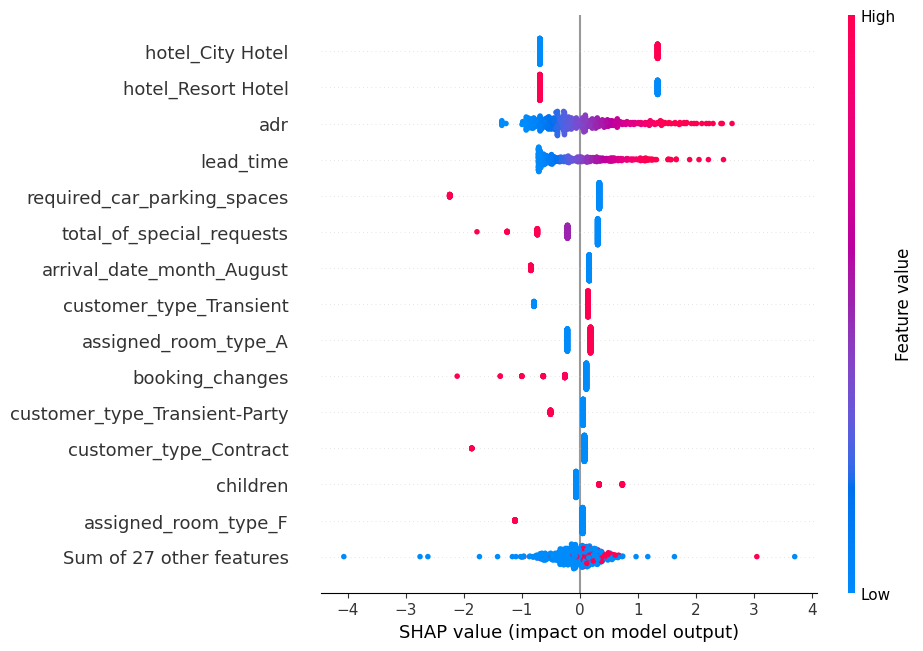

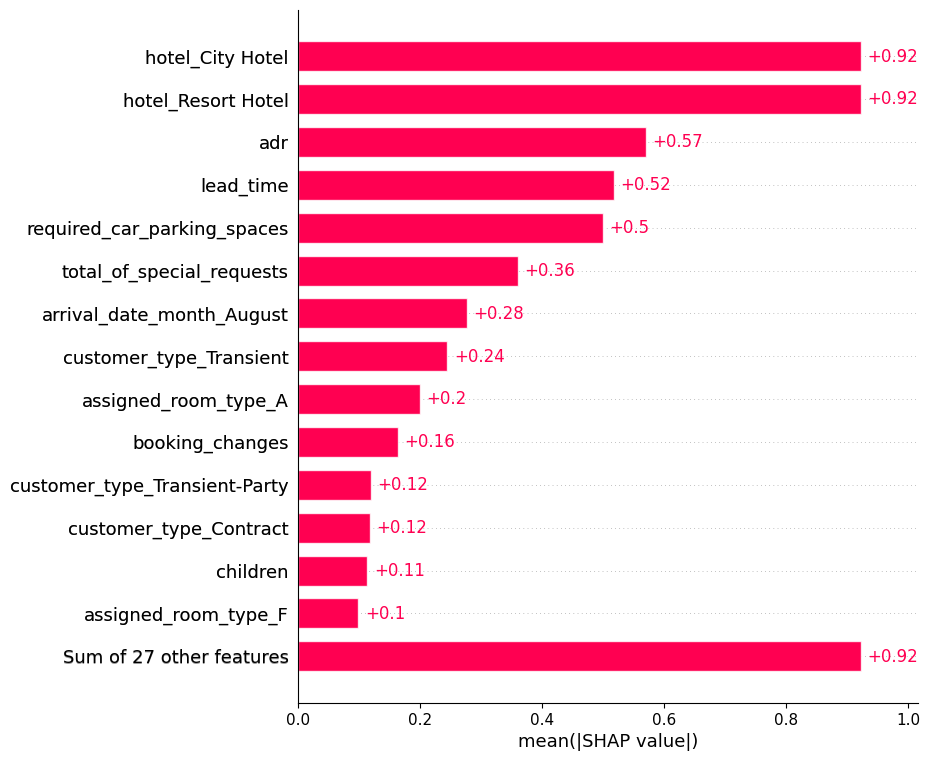

In [14]:
global_shap = sup.explain_global(
    data="test",
    sample_size=500,
    plots=("beeswarm", "bar"),
    top_n=15
)

# specific

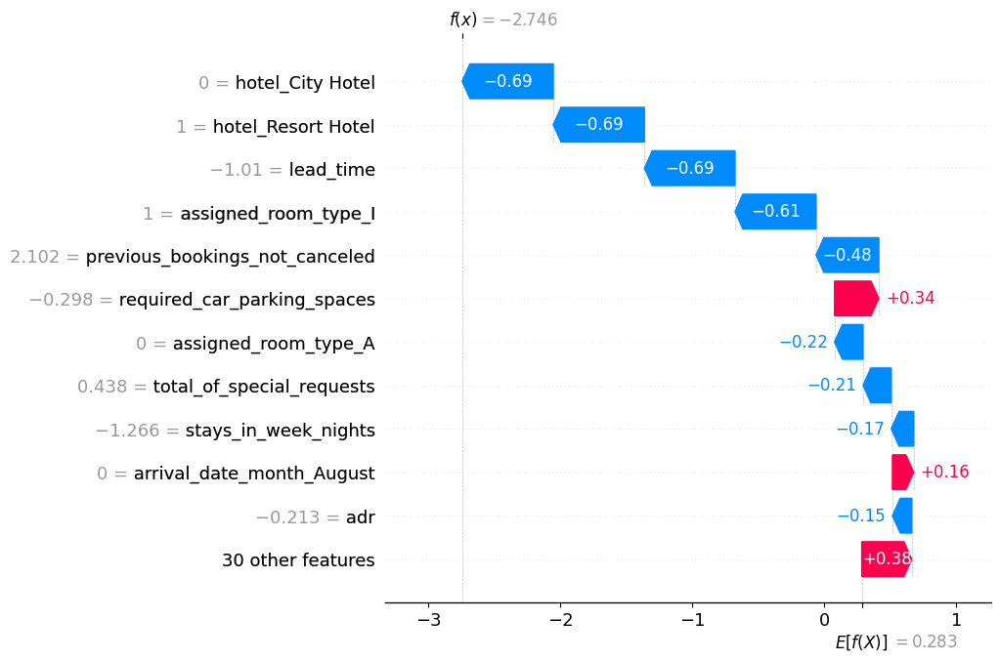

In [15]:
local_shap = sup.explain_instance(
    index=25,
    data="test",
    plot="waterfall",
    top_n=12
)

In [16]:
sup.pretty_table(
    local_shap["contributions"].head(12),
    title="SHAP contributions — observation 25"
)

SHAP contributions — observation 25


,feature,value,shap_value,abs_shap,direction
0,hotel_City Hotel,0.0000,-0.6909,0.6909,decreases output
1,hotel_Resort Hotel,1.0000,-0.6909,0.6909,decreases output
2,lead_time,-1.0095,-0.6867,0.6867,decreases output
3,assigned_room_type_I,1.0000,-0.6141,0.6141,decreases output
4,previous_bookings_not_canceled,2.1020,-0.4757,0.4757,decreases output
5,required_car_parking_spaces,-0.2982,0.3356,0.3356,increases output
6,assigned_room_type_A,0.0000,-0.2162,0.2162,decreases output
7,total_of_special_requests,0.4380,-0.2136,0.2136,decreases output
8,stays_in_week_nights,-1.2655,-0.1703,0.1703,decreases output
9,arrival_date_month_August,0.0000,0.1614,0.1614,increases output


In [17]:
sup.explain_summary(
    top_n=10
)

MODEL INTERPRETABILITY SUMMARY
Model: LDA
Target: is_canceled
Top 10 global SHAP drivers


,rank,feature,mean_abs_shap,mean_shap
0,1,hotel_Resort Hotel,0.9224,0.0325
1,2,hotel_City Hotel,0.9224,0.0325
2,3,adr,0.5696,0.0008
3,4,lead_time,0.5170,-0.0724
4,5,required_car_parking_spaces,0.4999,0.1136
5,6,total_of_special_requests,0.3600,-0.0146
6,7,arrival_date_month_August,0.2766,-0.0081
7,8,customer_type_Transient,0.2444,-0.0093
8,9,assigned_room_type_A,0.1990,-0.0016
9,10,booking_changes,0.1635,0.0260


,rank,feature,mean_abs_shap,mean_shap
0,1,hotel_Resort Hotel,0.922400,0.032513
1,2,hotel_City Hotel,0.922400,0.032513
2,3,adr,0.569638,0.000776
3,4,lead_time,0.517035,-0.072374
4,5,required_car_parking_spaces,0.499890,0.113588
5,6,total_of_special_requests,0.360008,-0.014584
6,7,arrival_date_month_August,0.276630,-0.008070
7,8,customer_type_Transient,0.244449,-0.009330
8,9,assigned_room_type_A,0.198995,-0.001601
9,10,booking_changes,0.163460,0.026005


In [18]:
# ==========================================================
# 11. Evaluación inicial
# ==========================================================

test_metrics = sup.evaluate_test()

sup.pretty_table(
    test_metrics,
    title="Test Metrics"
)


Test Metrics


,accuracy,balanced_accuracy,f1_macro,precision_macro,recall_macro,use_threshold,threshold,precision_positive,recall_positive,f1_positive,roc_auc,average_precision
0,0.8368,0.8424,0.8368,0.8430,0.8424,False,0.5000,0.9122,0.7714,0.8359,0.9280,0.9456


In [19]:
# ==========================================================
# 12. Optimización del threshold
# ==========================================================

thresholds = sup.optimize_threshold(
    objective="precision",
    constraint={
        "recall_min":0.75
    },
    use="valid"
)

sup.pretty_table(
    thresholds.head(10),
    title="Threshold Search"
)

Threshold Search


,threshold,precision_pos,recall_pos,f1_pos,objective_value,passes_constraint
0,0.0500,0.6156,0.9901,0.7592,0.6156,True
1,0.0600,0.6239,0.9879,0.7648,0.6239,True
2,0.0700,0.6305,0.9841,0.7686,0.6305,True
3,0.0800,0.6426,0.9780,0.7756,0.6426,True
4,0.0900,0.6523,0.9734,0.7811,0.6523,True
5,0.1000,0.6649,0.9666,0.7879,0.6649,True
6,0.1100,0.6748,0.9605,0.7927,0.6748,True
7,0.1200,0.6846,0.9568,0.7981,0.6846,True
8,0.1300,0.6944,0.9552,0.8042,0.6944,True
9,0.1400,0.7035,0.9507,0.8086,0.7035,True


In [20]:

# ==========================================================
# 13. Evaluación final
# ==========================================================

test_threshold = sup.evaluate_test(
    use_threshold=True
)

sup.pretty_table(
    test_threshold,
    title="Final Test Metrics"
)

Final Test Metrics


,accuracy,balanced_accuracy,f1_macro,precision_macro,recall_macro,use_threshold,threshold,precision_positive,recall_positive,f1_positive,roc_auc,average_precision
0,0.8381,0.8433,0.8381,0.8435,0.8433,True,0.4900,0.9103,0.7760,0.8378,0.9280,0.9456


In [21]:

# ==========================================================
# 14. Guardar modelo
# ==========================================================

sup.save("hotel_cancellation.pkl")

Modelo guardado exitosamente en: hotel_cancellation.pkl


'hotel_cancellation.pkl'

In [22]:
# ==========================================================
# 15. Resumen ejecutivo
# ==========================================================

sup.executive_report()

Resumen Ejecutivo de Clasificación


,target,positive_label,winning_model,decision_mode,threshold,accuracy,precision_positive,recall_positive,f1_positive,roc_auc,saved_path
0,is_canceled,Yes,LDA,optimized_threshold,0.4900,0.8381,0.9103,0.7760,0.8378,0.9280,hotel_cancellation.pkl


,target,positive_label,winning_model,decision_mode,threshold,accuracy,precision_positive,recall_positive,f1_positive,roc_auc,saved_path
0,is_canceled,Yes,LDA,optimized_threshold,0.49,0.838077,0.910256,0.775956,0.837758,0.927961,hotel_cancellation.pkl
